# Previsão de vendas do varejo de material de construção

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Carregando e preparando os dados](#data_review)
    * [Conclusões](#data_review_conclusions)
* [Etapa 2. Análise exploratória (EDA)](#eda)
    * [Conclusões](#eda_conclusions)
* [Etapa 3. Preparação para a modelagem](#preparation)
* [Etapa 4. Modelos de previsão](#model)
* [Etapa 5. Validação e comparação dos modelos](#validation)
* [Etapa 6. Previsão dos próximos 12 meses](#forecast)
* [Conclusão geral](#end)

## Introdução <a id='intro'></a>

Para um home center, saber quanto o mercado vai vender nos próximos meses orienta decisões de **compras, estoque, escala de equipes e metas**. Comprar demais imobiliza capital; comprar de menos significa ruptura e venda perdida.

Neste projeto, vou prever o **volume de vendas do varejo de material de construção no Brasil para os próximos 12 meses**, usando dados públicos do IBGE.

### Objetivo:
- Entender o comportamento das vendas ao longo do tempo: tendência, sazonalidade e choques
- Verificar se o calendário (dias úteis e sábados de cada mês) influencia as vendas
- Comparar modelos de previsão com uma validação que simula o uso real
- Escolher o melhor modelo e gerar a previsão dos próximos 12 meses

### Descrição dos dados
- **Fonte:** IBGE, Pesquisa Mensal de Comércio (PMC), tabela 8883, disponível em https://sidra.ibge.gov.br/tabela/8883
- **Variável:** índice de volume de vendas do varejo de material de construção, base 2022 = 100, **sem ajuste sazonal**
- **Arquivo:** `tabela8883.csv`, baixado do SIDRA no formato CSV (BR)

O índice de **volume** mede a quantidade vendida, sem o efeito da inflação. Escolhi a série **sem ajuste sazonal** porque a sazonalidade faz parte do que o modelo precisa prever.
[Voltar ao Índice](#back)

## Etapa 1. Carregando e preparando os dados <a id='data_review'></a>

### Instalando e importando as bibliotecas

Se estiver usando o Google Colab ou outro Jupyter online, as bibliotecas abaixo já costumam estar instaladas. Se alguma faltar, basta tirar o `#` da linha de instalação e rodar a célula.

In [1]:
# Instalação das bibliotecas (só é necessário se alguma não estiver instalada)
# %pip install pandas numpy matplotlib statsmodels lightgbm

In [2]:
# Importa as bibliotecas necessárias
import calendar  # Utilizada para calcular dias úteis e sábados de cada mês
import csv  # Utilizada para ler o arquivo do IBGE linha por linha
import os  # Utilizada para verificar se o arquivo de dados existe na pasta
import time  # Utilizada para medir o tempo de treinamento dos modelos
import warnings  # Utilizada para esconder avisos que não afetam o resultado
from itertools import product  # Utilizada para montar a grade de parâmetros do SARIMA

import numpy as np  # Utilizada para operações numéricas
import pandas as pd  # Utilizada para manipulação de dados em DataFrames
import matplotlib.pyplot as plt  # Utilizada para a construção de gráficos
import lightgbm as lgb  # Modelo de machine learning baseado em árvores (boosting)
from statsmodels.tsa.seasonal import STL  # Decomposição da série em tendência, sazonalidade e resíduo
from statsmodels.tsa.holtwinters import ExponentialSmoothing  # Modelo Holt-Winters
from statsmodels.tsa.statespace.sarimax import SARIMAX  # Modelo SARIMA

warnings.filterwarnings("ignore")  # Esconde avisos de convergência que não afetam o resultado

# Padroniza a aparência de todos os gráficos do notebook
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# Cores usadas nos gráficos
AZUL, LARANJA, CINZA = "#1f4e79", "#e07b00", "#9aa5b1"
MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

### Lendo o arquivo do IBGE

O notebook procura o arquivo `tabela8883.csv` na mesma pasta. No Google Colab, envie o arquivo pelo ícone de pasta, na barra lateral esquerda. Se o arquivo não estiver na pasta, o notebook baixa a cópia que está no repositório do GitHub.

In [3]:
# Caminho do arquivo local e cópia no GitHub (usada se o arquivo não estiver na pasta)
ARQUIVO = "tabela8883.csv"
URL_GITHUB = "https://raw.githubusercontent.com/gabrieldeoliver1/Projetos/main/Projeto_17/tabela8883.csv"

# Se o arquivo não estiver na pasta, baixa do GitHub
if not os.path.exists(ARQUIVO):
    import urllib.request  # Utilizada para baixar o arquivo
    urllib.request.urlretrieve(URL_GITHUB, ARQUIVO)
    print("Arquivo baixado do GitHub.")

# Lê o arquivo do IBGE: separador ';' e codificação UTF-8 com BOM
with open(ARQUIVO, encoding="utf-8-sig") as f:
    linhas = list(csv.reader(f, delimiter=";"))

# Mostra as primeiras linhas para entender a estrutura do arquivo
for linha in linhas[:6]:
    print(linha[:4])

['Tabela 8883 - Índice e variação da receita nominal e do volume de vendas no comércio varejista ampliado, por atividades (2022 = 100)']
['Variável - PMC - Número-índice (2022=100) (Número-índice)']
['', 'Atividades', 'Mês x Tipos de índice']
['', 'Atividades', 'janeiro 2000', 'fevereiro 2000']
['', 'Atividades', 'Índice de volume de vendas no comércio varejista ampliado', 'Índice de volume de vendas no comércio varejista ampliado']
['Brasil', 'Material de construção', '-', '-']


O arquivo do IBGE vem no **formato largo**: cada mês é uma coluna, e há linhas de título antes dos dados. Para trabalhar com séries temporais, preciso do **formato longo**, com uma linha por mês. O IBGE também usa `-` para indicar meses sem informação.

In [4]:
# Dicionário para converter o nome do mês em número
NUMERO_DO_MES = {"janeiro": 1, "fevereiro": 2, "março": 3, "abril": 4, "maio": 5, "junho": 6,
                 "julho": 7, "agosto": 8, "setembro": 9, "outubro": 10, "novembro": 11, "dezembro": 12}

# Localiza a linha com os meses (cabeçalho) e a linha com os valores de material de construção
cabecalho = next(l for l in linhas if len(l) > 2 and l[2] == "janeiro 2000")[2:]
valores = next(l for l in linhas if len(l) > 2 and l[1] == "Material de construção")[2:]

# Converte cada par (mês, valor) em uma linha da tabela
registros = []
for mes_ano, valor in zip(cabecalho, valores):
    mes, ano = mes_ano.split()  # Ex.: 'janeiro 2000' -> 'janeiro', '2000'
    if valor.strip() in {"-", "...", "X", ""}:  # Convenções do IBGE para valor indisponível
        continue
    data = pd.Timestamp(int(ano), NUMERO_DO_MES[mes], 1)  # Primeiro dia do mês
    registros.append((data, float(valor.replace(",", "."))))  # Troca a vírgula decimal por ponto

# Cria a série mensal, com a data como índice e frequência mensal ('MS' = início do mês)
serie = pd.DataFrame(registros, columns=["data", "indice"]).set_index("data")["indice"].asfreq("MS")
serie.head()

data
2003-01-01    62.26781
2003-02-01    59.37559
2003-03-01    57.50415
2003-04-01    57.24895
2003-05-01    59.97104
Freq: MS, Name: indice, dtype: float64

In [5]:
# Verifica o tamanho, o período e se há meses faltantes
print(f"Quantidade de meses: {len(serie)}")
print(f"Período: {serie.index.min():%m/%Y} a {serie.index.max():%m/%Y}")
print(f"Meses faltantes: {serie.isna().sum()}")
serie.describe().round(2)

Quantidade de meses: 283
Período: 01/2003 a 07/2026
Meses faltantes: 0


count    283.00
mean      85.59
std       17.59
min       49.34
25%       70.01
50%       88.55
75%       99.46
max      128.72
Name: indice, dtype: float64

### Conclusões <a id='data_review_conclusions'></a>

- A série começa em **janeiro de 2003**: de 2000 a 2002, a atividade de material de construção não tem dados na tabela.
- São **283 meses**, sem nenhum mês faltante, o que é ideal para modelos de séries temporais.
- O índice tem base **2022 = 100**: um valor de 110 significa um volume de vendas 10% acima da média de 2022.
[Voltar ao Índice](#back)

## Etapa 2. Análise exploratória (EDA) <a id='eda'></a>

### Tendência e choques

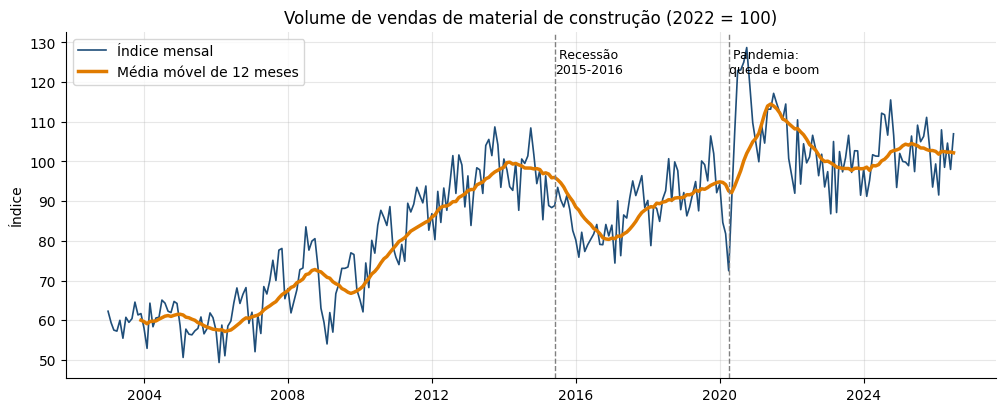

In [6]:
# Gráfico da série com a média móvel de 12 meses, que suaviza a sazonalidade e mostra a tendência
fig, ax = plt.subplots()
ax.plot(serie, color=AZUL, lw=1.2, label="Índice mensal")
ax.plot(serie.rolling(12).mean(), color=LARANJA, lw=2.5, label="Média móvel de 12 meses")

# Marca os dois principais choques do período
for data, texto in [("2015-06", "Recessão\n2015-2016"), ("2020-04", "Pandemia:\nqueda e boom")]:
    ax.axvline(pd.Timestamp(data), color="gray", ls="--", lw=1)
    ax.text(pd.Timestamp(data), serie.max() * 0.95, " " + texto, fontsize=9)

ax.set_title("Volume de vendas de material de construção (2022 = 100)")
ax.set_ylabel("Índice")
ax.legend()
plt.show()

In [7]:
# Variação anual do volume médio de vendas (2026 considera só os meses disponíveis)
media_anual = serie.groupby(serie.index.year).mean()
variacao_anual = (media_anual.pct_change() * 100).round(1)
print("Variação anual do volume de vendas (%):")
print(variacao_anual.tail(10).to_string())

# Mês de maior volume de toda a série
print(f"\nMaior volume da série: {serie.max():.1f} em {serie.idxmax():%m/%Y}")

Variação anual do volume de vendas (%):
data
2017     9.2
2018     3.5
2019     4.2
2020    10.8
2021     4.4
2022    -8.7
2023    -1.8
2024     4.8
2025    -0.1
2026    -1.7

Maior volume da série: 128.7 em 10/2020


Podemos observar que a série cresce até 2013-2014, cai com a **recessão de 2015-2016** e tem o maior pico da história em **outubro de 2020**, quando as pessoas passaram mais tempo em casa e investiram em reformas. Depois do pico, as vendas voltaram a um patamar estável, perto de 100. Esses choques são o maior desafio para qualquer modelo de previsão.

### Decomposição da série

A decomposição **STL** separa a série em três partes: **tendência** (direção de longo prazo), **sazonalidade** (padrão que se repete todo ano) e **resíduo** (o que sobra, incluindo os choques).

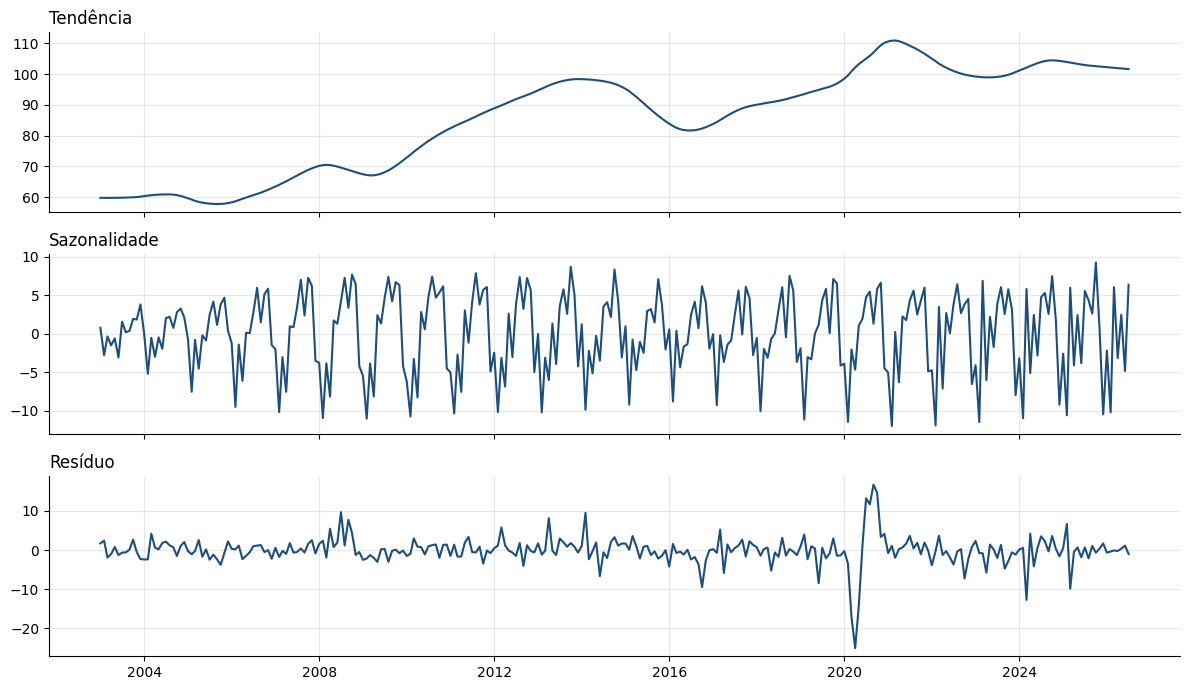

Força da sazonalidade: 0.67


In [8]:
# Decomposição STL com período de 12 meses; robust=True reduz a influência de valores extremos
stl = STL(serie, period=12, robust=True).fit()

# Plota as três componentes
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, componente, titulo in zip(axs, [stl.trend, stl.seasonal, stl.resid], ["Tendência", "Sazonalidade", "Resíduo"]):
    ax.plot(componente, color=AZUL)
    ax.set_title(titulo, loc="left")
plt.tight_layout()
plt.show()

# Força da sazonalidade: 0 = nenhuma, 1 = muito forte
forca_sazonal = 1 - np.var(stl.resid) / np.var(stl.resid + stl.seasonal)
print(f"Força da sazonalidade: {forca_sazonal:.2f}")

### Perfil sazonal: quais meses vendem mais?

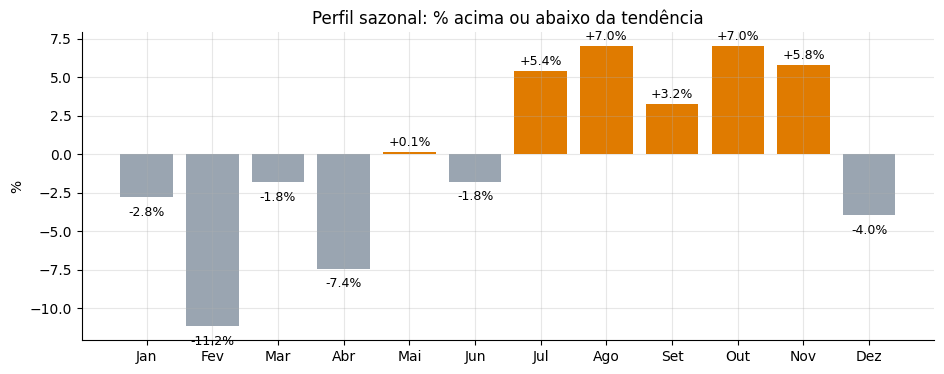

In [9]:
# Para cada mês, calcula quanto as vendas ficam acima ou abaixo da tendência, em média
perfil_sazonal = ((serie / stl.trend).groupby(serie.index.month).mean() - 1) * 100

# Barras laranjas: meses acima da tendência; cinzas: meses abaixo
cores = [LARANJA if v > 0 else CINZA for v in perfil_sazonal.values]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(MESES, perfil_sazonal.values, color=cores)
for i, v in enumerate(perfil_sazonal.values):
    ax.text(i, v + (0.4 if v > 0 else -1.2), f"{v:+.1f}%", ha="center", fontsize=9)
ax.set_title("Perfil sazonal: % acima ou abaixo da tendência")
ax.set_ylabel("%")
plt.show()

O **segundo semestre** concentra as melhores vendas: de julho a novembro, o volume fica de 3% a 7% acima da tendência. **Fevereiro** é o mês mais fraco, cerca de 11% abaixo. Uma hipótese é que parte dessa diferença venha do **calendário**: fevereiro tem menos dias e, em geral, menos dias úteis.

### O calendário influencia as vendas?

Vou contar, para cada mês, o número de **dias úteis** (segunda a sexta) e de **sábados**, um dia forte de vendas para o varejo de material de construção.

In [10]:
def features_calendario(datas):
    """Calcula os dias úteis, os sábados e o total de dias de cada mês."""
    linhas = []
    for d in datas:
        dias_no_mes = calendar.monthrange(d.year, d.month)[1]  # Quantidade de dias do mês
        # Dia da semana de cada dia do mês: 0 = segunda ... 5 = sábado, 6 = domingo
        dias_da_semana = [calendar.weekday(d.year, d.month, dia) for dia in range(1, dias_no_mes + 1)]
        linhas.append({
            "dias_uteis": sum(w < 5 for w in dias_da_semana),  # Segunda a sexta
            "sabados": sum(w == 5 for w in dias_da_semana),
            "dias_no_mes": dias_no_mes,
        })
    return pd.DataFrame(linhas, index=datas)


calendario = features_calendario(serie.index)

# Desvio em relação à tendência (%), agrupado pelo número de dias úteis e de sábados
desvio = (serie / stl.trend - 1) * 100
print("Desvio médio da tendência (%) por número de dias úteis:")
print(desvio.groupby(calendario["dias_uteis"]).mean().round(1).to_string())
print("\nDesvio médio da tendência (%) por número de sábados:")
print(desvio.groupby(calendario["sabados"]).mean().round(1).to_string())

Desvio médio da tendência (%) por número de dias úteis:
dias_uteis
20   -8.0
21   -1.7
22    1.1
23    3.6

Desvio médio da tendência (%) por número de sábados:
sabados
4    0.2
5   -0.7


A relação com os **dias úteis** é clara: meses com 20 dias úteis ficam cerca de 8% abaixo da tendência, e meses com 23 ficam cerca de 4% acima. Para os **sábados**, a comparação simples não mostra diferença, porque meses com 5 sábados costumam ter menos dias úteis, e um efeito esconde o outro. Por isso, as duas variáveis vão entrar **juntas** no modelo SARIMA, que consegue separar o efeito de cada uma.

### Conclusões <a id='eda_conclusions'></a>

- A série tem **tendência** de longo prazo e **sazonalidade forte** (força de 0,67).
- O segundo semestre vende mais, e fevereiro é o mês mais fraco.
- **Choques** como a recessão de 2015-2016 e a pandemia causam os maiores desvios.
- O **número de dias úteis** está claramente ligado às vendas e será testado como variável do modelo.
[Voltar ao Índice](#back)

## Etapa 3. Preparação para a modelagem <a id='preparation'></a>

### Estratégia de validação: origem móvel

Em séries temporais, **não se pode embaralhar os dados**: isso faria o modelo "ver o futuro" e inflaria os resultados. Por isso uso a validação por **origem móvel**, que simula o uso real:

1. Escolho um ponto de corte (por exemplo, janeiro de 2023).
2. Treino o modelo só com os dados até esse ponto.
3. Prevejo os **12 meses seguintes** e comparo com o que realmente aconteceu.
4. Repito para **6 pontos de corte**, a cada 6 meses, de janeiro de 2023 a julho de 2025.

### Métricas
- **MAPE** (erro percentual absoluto médio): o erro médio em %, fácil de comunicar para o negócio. É a métrica principal.
- **RMSE** (raiz do erro quadrático médio): o erro na unidade do índice, que penaliza mais os erros grandes.

In [11]:
HORIZONTE = 12  # Quantidade de meses previstos à frente
CORTES = pd.date_range("2023-01-01", "2025-07-01", freq="6MS")  # 6 pontos de corte semestrais
print("Pontos de corte:", [f"{c:%m/%Y}" for c in CORTES])


def mape(real, previsto):
    """Erro percentual absoluto médio, em %."""
    real, previsto = np.asarray(real), np.asarray(previsto)
    return np.mean(np.abs((real - previsto) / real)) * 100


def rmse(real, previsto):
    """Raiz do erro quadrático médio."""
    real, previsto = np.asarray(real), np.asarray(previsto)
    return np.sqrt(np.mean((real - previsto) ** 2))


def meses_futuros(treino, horizonte):
    """Datas dos meses seguintes ao fim do treino."""
    return pd.date_range(treino.index[-1] + pd.offsets.MonthBegin(1), periods=horizonte, freq="MS")

Pontos de corte: ['01/2023', '07/2023', '01/2024', '07/2024', '01/2025', '07/2025']



[Voltar ao Índice](#back)

## Etapa 4. Modelos de previsão <a id='model'></a>

Vou comparar cinco abordagens, da mais simples à mais sofisticada. Todas recebem a série de treino e devolvem a previsão dos próximos meses.

### Modelo 0: Sazonal ingênuo (linha de base)

Repete o valor do mesmo mês do ano anterior. Parece simples demais, mas é difícil de vencer em séries com sazonalidade forte. **Um modelo só vale a pena se for melhor que essa linha de base.**

In [12]:
def sazonal_ingenuo(treino, horizonte):
    """Previsão = valor do mesmo mês do ano anterior."""
    datas = meses_futuros(treino, horizonte)
    valores = [treino[d - pd.DateOffset(years=1)] for d in datas]
    return pd.Series(valores, index=datas)

### Modelo 1: Holt-Winters

Suavização exponencial com **tendência amortecida** (a tendência perde força com o tempo, evitando previsões exageradas) e **sazonalidade multiplicativa** (o efeito sazonal é proporcional ao nível das vendas).

In [13]:
def holt_winters(treino, horizonte):
    """Suavização exponencial com tendência amortecida e sazonalidade multiplicativa."""
    modelo = ExponentialSmoothing(treino, trend="add", damped_trend=True,
                                  seasonal="mul", seasonal_periods=12).fit(optimized=True)
    return modelo.forecast(horizonte)

### Modelo 2: SARIMA com variáveis de calendário

O **SARIMA** modela a série a partir dos seus próprios valores passados e erros, com uma parte sazonal de 12 meses. Três escolhas importantes:

- Uso o **logaritmo** da série, para que os efeitos sejam percentuais e a previsão nunca fique negativa.
- Uso **dias úteis e sábados** como variáveis externas.
- A **ordem** do modelo (os parâmetros p, q, P e Q) é escolhida pelo critério **AIC**, que equilibra qualidade do ajuste e simplicidade, usando só os dados anteriores ao primeiro ponto de corte. Assim, a escolha não usa nenhuma informação dos períodos de teste.

In [14]:
def escolher_ordem_sarima(treino, usar_calendario=True):
    """Testa uma grade de ordens SARIMA e devolve a de menor AIC."""
    exog = features_calendario(treino.index)[["dias_uteis", "sabados"]] if usar_calendario else None
    melhor_aic, melhor_ordem = np.inf, None
    # Grade: p em {0,1,2}, q em {0,1}, P em {0,1}, Q em {0,1}; d = 1 e D = 1 (uma diferença simples e uma sazonal)
    for p, q, P, Q in product([0, 1, 2], [0, 1], [0, 1], [0, 1]):
        try:
            ajuste = SARIMAX(np.log(treino), exog=exog, order=(p, 1, q),
                             seasonal_order=(P, 1, Q, 12)).fit(disp=False)
        except Exception:
            continue
        if ajuste.aic < melhor_aic:
            melhor_aic, melhor_ordem = ajuste.aic, ((p, 1, q), (P, 1, Q, 12))
    return melhor_ordem, melhor_aic


# Escolhe a ordem com os dados até o primeiro ponto de corte (sem olhar os períodos de teste)
inicio = time.time()
ORDEM_CAL, aic_cal = escolher_ordem_sarima(serie[:CORTES[0]], usar_calendario=True)
ORDEM_SEM, aic_sem = escolher_ordem_sarima(serie[:CORTES[0]], usar_calendario=False)
print(f"SARIMA com calendário: ordem {ORDEM_CAL[0]}x{ORDEM_CAL[1]} (AIC {aic_cal:.1f})")
print(f"SARIMA sem calendário: ordem {ORDEM_SEM[0]}x{ORDEM_SEM[1]} (AIC {aic_sem:.1f})")
print(f"Tempo da busca: {time.time() - inicio:.0f} segundos")

SARIMA com calendário: ordem (1, 1, 0)x(1, 1, 1, 12) (AIC -732.9)
SARIMA sem calendário: ordem (2, 1, 1)x(1, 1, 1, 12) (AIC -663.0)
Tempo da busca: 15 segundos


In [15]:
def sarima(treino, horizonte, ordem=None, usar_calendario=True, intervalo=False):
    """SARIMA sobre o log da série, com ou sem as variáveis de calendário."""
    if ordem is None:
        ordem = ORDEM_CAL if usar_calendario else ORDEM_SEM
    colunas = ["dias_uteis", "sabados"]
    exog = features_calendario(treino.index)[colunas] if usar_calendario else None
    ajuste = SARIMAX(np.log(treino), exog=exog, order=ordem[0], seasonal_order=ordem[1]).fit(disp=False)

    datas = meses_futuros(treino, horizonte)
    exog_futuro = features_calendario(datas)[colunas] if usar_calendario else None
    previsao = ajuste.get_forecast(horizonte, exog=exog_futuro)

    media = np.exp(previsao.predicted_mean)  # Volta do log para a escala do índice
    media.index = datas
    if not intervalo:
        return media
    ic = np.exp(previsao.conf_int(alpha=0.05))  # Intervalo de confiança de 95%
    ic.index = datas
    ic.columns = ["limite_inferior", "limite_superior"]
    return media, ic, ajuste


def sarima_sem_calendario(treino, horizonte):
    """Mesmo modelo, sem dias úteis e sábados, para medir o ganho dessas variáveis."""
    return sarima(treino, horizonte, usar_calendario=False)

### Modelo 3: LightGBM

Modelo de machine learning baseado em árvores de decisão (gradient boosting). As variáveis de entrada são os valores de meses anteriores (**defasagens**), médias móveis, o mês do ano e o calendário.

Modelos de árvore **não conseguem extrapolar tendência**: eles só preveem valores parecidos com os que viram no treino. Por isso, o alvo do modelo é a **variação em relação ao mesmo mês do ano anterior**, e a previsão é feita mês a mês (de forma recursiva), usando cada previsão para calcular as variáveis do mês seguinte.

In [16]:
DEFASAGENS = [1, 2, 3, 6, 12, 24]  # Meses anteriores usados como variáveis


def tabela_ml(s):
    """Monta a tabela de variáveis do LightGBM a partir da série."""
    df = pd.DataFrame({"y": s})
    for d in DEFASAGENS:
        df[f"lag_{d}"] = s.shift(d)  # Valor de d meses atrás
    df["media_3m"] = s.shift(1).rolling(3).mean()  # Média dos 3 meses anteriores
    df["media_12m"] = s.shift(1).rolling(12).mean()  # Média dos 12 meses anteriores
    df["mes"] = s.index.month
    return df.join(features_calendario(s.index))


def lightgbm_recursivo(treino, horizonte):
    """LightGBM que prevê a variação anual (em log) e avança mês a mês."""
    tabela = tabela_ml(treino).dropna()
    X = tabela.drop(columns="y")
    y = np.log(tabela["y"]) - np.log(tabela["lag_12"])  # Alvo: variação em relação ao ano anterior
    modelo = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=10,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=42, verbose=-1)
    modelo.fit(X, y)

    historico = treino.copy()
    for data in meses_futuros(treino, horizonte):
        historico.loc[data] = np.nan  # Abre o próximo mês
        linha = tabela_ml(historico.asfreq("MS")).loc[[data]].drop(columns="y")
        variacao = modelo.predict(linha)[0]
        # Previsão = mesmo mês do ano anterior x variação prevista
        historico.loc[data] = historico[data - pd.DateOffset(years=1)] * np.exp(variacao)
    return historico.iloc[-horizonte:]

### Modelo 4: Combinação

Média simples das previsões de Holt-Winters, SARIMA e LightGBM. Combinar modelos diferentes costuma reduzir o risco de um modelo errar muito sozinho.

In [17]:
# Dicionário com todos os modelos que serão avaliados
MODELOS = {
    "Sazonal ingênuo (linha de base)": sazonal_ingenuo,
    "Holt-Winters": holt_winters,
    "SARIMA com calendário": sarima,
    "SARIMA sem calendário": sarima_sem_calendario,
    "LightGBM": lightgbm_recursivo,
}



[Voltar ao Índice](#back)

## Etapa 5. Validação e comparação dos modelos <a id='validation'></a>

Para cada ponto de corte, treino todos os modelos com o passado e comparo a previsão dos 12 meses seguintes com o valor real. Esta célula leva cerca de 1 a 2 minutos.

In [18]:
resultados = []
inicio = time.time()

for corte in CORTES:
    treino = serie[:corte]  # Só o passado
    teste = serie[corte + pd.offsets.MonthBegin(1):][:HORIZONTE]  # Os 12 meses seguintes

    previsoes_corte = {}
    for nome, funcao in MODELOS.items():
        previsto = funcao(treino, HORIZONTE).loc[teste.index]
        previsoes_corte[nome] = previsto
        resultados.append({"corte": corte, "modelo": nome, "MAPE": mape(teste, previsto),
                           "RMSE": rmse(teste, previsto)})

    # Combinação: média dos três modelos principais
    combinacao = (previsoes_corte["Holt-Winters"] + previsoes_corte["SARIMA com calendário"]
                  + previsoes_corte["LightGBM"]) / 3
    resultados.append({"corte": corte, "modelo": "Combinação (média de 3 modelos)",
                       "MAPE": mape(teste, combinacao), "RMSE": rmse(teste, combinacao)})

resultados = pd.DataFrame(resultados)
print(f"Validação concluída em {time.time() - inicio:.0f} segundos")

Validação concluída em 10 segundos


In [19]:
# Resumo: média do MAPE e do RMSE nas 6 janelas, ordenado do menor para o maior erro
resumo = resultados.groupby("modelo")[["MAPE", "RMSE"]].mean().sort_values("MAPE")
mape_base = resumo.loc["Sazonal ingênuo (linha de base)", "MAPE"]
resumo["Ganho sobre a linha de base (%)"] = (1 - resumo["MAPE"] / mape_base) * 100
resumo.round(2)

,MAPE,RMSE,Ganho sobre a linha de base (%)
modelo,,,
SARIMA com calendário,3.37,4.30,24.94
Combinação (média de 3 modelos),3.40,4.48,24.22
Holt-Winters,3.61,4.48,19.55
SARIMA sem calendário,3.66,4.57,18.47
Sazonal ingênuo (linha de base),4.48,5.66,0.00
LightGBM,5.61,6.93,-25.17


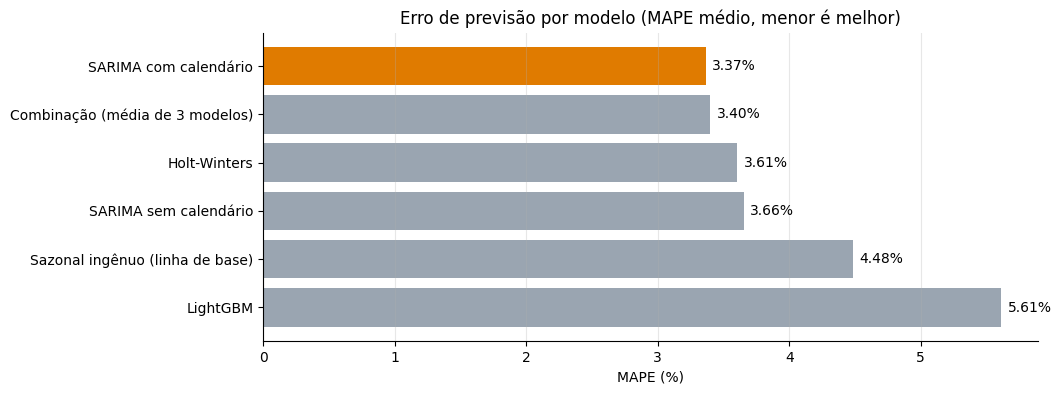

In [20]:
# Gráfico de barras com o MAPE médio de cada modelo (o vencedor em laranja)
ordenado = resumo.sort_values("MAPE", ascending=False)
vencedor = resumo.index[0]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(ordenado.index, ordenado["MAPE"], color=[LARANJA if m == vencedor else CINZA for m in ordenado.index])
for i, v in enumerate(ordenado["MAPE"]):
    ax.text(v + 0.05, i, f"{v:.2f}%", va="center")
ax.set_title("Erro de previsão por modelo (MAPE médio, menor é melhor)")
ax.set_xlabel("MAPE (%)")
ax.grid(axis="y", visible=False)
plt.show()

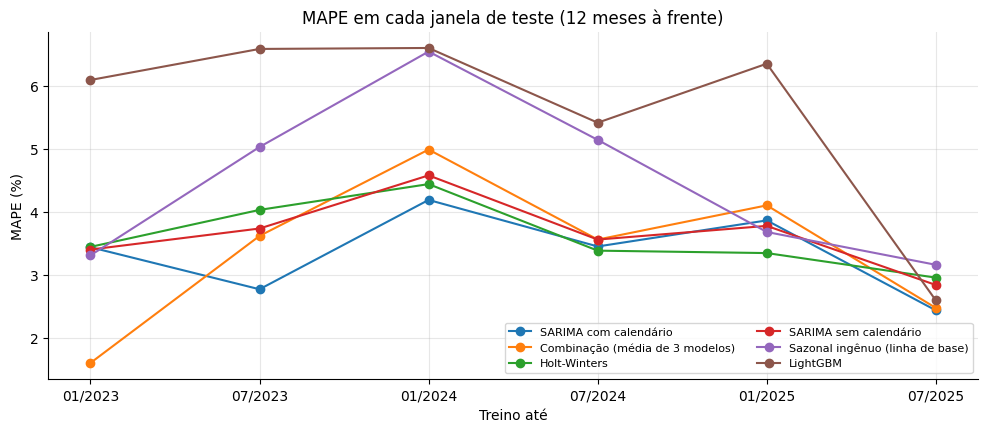

In [21]:
# MAPE de cada modelo em cada janela de teste: mostra se o desempenho é consistente
por_janela = resultados.pivot(index="corte", columns="modelo", values="MAPE")[resumo.index]
por_janela.index = por_janela.index.strftime("%m/%Y")
ax = por_janela.plot(marker="o", figsize=(12, 4.5))
ax.set_title("MAPE em cada janela de teste (12 meses à frente)")
ax.set_xlabel("Treino até")
ax.set_ylabel("MAPE (%)")
ax.legend(fontsize=8, ncol=2)
plt.show()

In [22]:
# Efeito de cada variável de calendário no modelo SARIMA treinado com toda a série
_, _, ajuste_completo = sarima(serie, HORIZONTE, intervalo=True)
efeito_dia_util = np.expm1(ajuste_completo.params["dias_uteis"]) * 100  # O modelo usa log: exp(coef) - 1
efeito_sabado = np.expm1(ajuste_completo.params["sabados"]) * 100
print(f"Cada dia útil a mais no mês: {efeito_dia_util:+.1f}% no volume de vendas")
print(f"Cada sábado a mais no mês (mantidos os dias úteis): {efeito_sabado:+.1f}%")

ganho_calendario = (1 - resumo.loc["SARIMA com calendário", "MAPE"] / resumo.loc["SARIMA sem calendário", "MAPE"]) * 100
print(f"Redução do erro do SARIMA ao incluir o calendário: {ganho_calendario:.1f}%")

Cada dia útil a mais no mês: +3.2% no volume de vendas
Cada sábado a mais no mês (mantidos os dias úteis): +1.5%
Redução do erro do SARIMA ao incluir o calendário: 7.9%


### Conclusões

- O **SARIMA com calendário** teve o menor erro médio: **3,37%**, cerca de **25% menor** que a linha de base. Ele será o modelo final.
- **O calendário importa:** cada dia útil a mais no mês soma cerca de **3,2%** ao volume de vendas, e cada sábado, cerca de **1,5%**. Sem essas variáveis, o mesmo SARIMA erra cerca de 8% a mais. Isso confirma a hipótese levantada na análise exploratória.
- A **combinação** de modelos chega muito perto do SARIMA, mas não o supera.
- O **LightGBM ficou pior que a linha de base.** Com 283 observações mensais, há poucos dados para um modelo de árvores aprender padrões que os modelos estatísticos já capturam bem. É um lembrete de que o modelo mais sofisticado nem sempre é o melhor, e de por que sempre comparar com uma linha de base.


[Voltar ao Índice](#back)

## Etapa 6. Previsão dos próximos 12 meses <a id='forecast'></a>

Com o modelo escolhido, treino com **toda a série** e prevejo os próximos 12 meses, com intervalo de confiança de 95%.

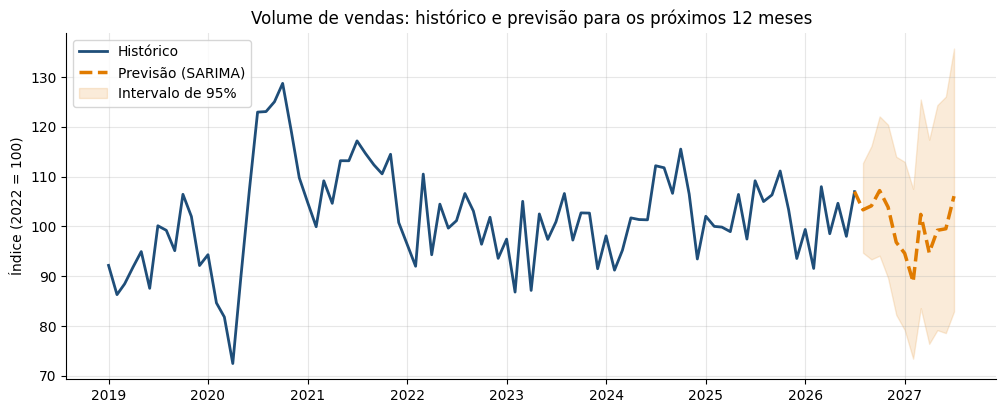

,previsao,limite_inferior,limite_superior
Ago/2026,103.3,94.7,112.7
Set/2026,104.1,93.4,116.1
Out/2026,107.2,94.1,122.1
Nov/2026,103.9,89.6,120.4
Dez/2026,96.8,82.2,114.0
Jan/2027,94.6,79.2,113.0
Fev/2027,88.9,73.4,107.5
Mar/2027,102.4,83.6,125.5
Abr/2027,94.7,76.4,117.4
Mai/2027,99.2,79.2,124.4


In [23]:
# Treina o SARIMA com toda a série e gera a previsão com intervalo de confiança
previsao, intervalo, _ = sarima(serie, HORIZONTE, intervalo=True)

# Gráfico: histórico desde 2019, previsão e intervalo de 95%
fig, ax = plt.subplots()
historico = serie["2019":]
ax.plot(historico, color=AZUL, lw=2, label="Histórico")
ax.plot([historico.index[-1], *previsao.index], [historico.iloc[-1], *previsao.values],
        color=LARANJA, lw=2.5, ls="--", label="Previsão (SARIMA)")
ax.fill_between(previsao.index, intervalo["limite_inferior"], intervalo["limite_superior"],
                color=LARANJA, alpha=0.15, label="Intervalo de 95%")
ax.set_title("Volume de vendas: histórico e previsão para os próximos 12 meses")
ax.set_ylabel("Índice (2022 = 100)")
ax.legend()
plt.show()

# Tabela com a previsão mês a mês
tabela_previsao = pd.concat([previsao.rename("previsao"), intervalo], axis=1).round(1)
tabela_previsao.index = [f"{MESES[d.month - 1]}/{d.year}" for d in tabela_previsao.index]
tabela_previsao

In [24]:
# Compara a média prevista com a média dos últimos 12 meses
variacao = (previsao.mean() / serie.iloc[-12:].mean() - 1) * 100
print(f"Média dos últimos 12 meses: {serie.iloc[-12:].mean():.1f}")
print(f"Média prevista para os próximos 12 meses: {previsao.mean():.1f} ({variacao:+.1f}%)")

Média dos últimos 12 meses: 102.2
Média prevista para os próximos 12 meses: 100.1 (-2.1%)


A previsão aponta para uma **leve retração, de cerca de 2%** em relação aos últimos 12 meses, mantendo a sazonalidade: os meses de agosto a novembro de 2026 ficam acima de 100, e fevereiro de 2027 é o mês mais fraco. O intervalo de confiança se abre com o horizonte: quanto mais distante o mês, maior a incerteza.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

Neste projeto, previ o volume de vendas do varejo de material de construção no Brasil para os próximos 12 meses, a partir de 283 meses de dados do IBGE.

**Principais resultados:**

- A série tem tendência de longo prazo, **sazonalidade forte** (segundo semestre mais forte e fevereiro como mês mais fraco) e foi marcada por dois grandes choques: a recessão de 2015-2016 e o boom de reformas na pandemia, com o pico histórico em outubro de 2020.
- O **calendário influencia as vendas**: cada dia útil a mais soma cerca de 3,2% ao volume do mês, e cada sábado, cerca de 1,5%.
- Entre os modelos avaliados em 6 janelas de teste, o **SARIMA com variáveis de calendário** teve o menor erro médio (**MAPE de 3,37%**), cerca de **25% melhor** que repetir o ano anterior. O LightGBM, mais sofisticado, ficou pior que a linha de base.
- A previsão para os próximos 12 meses aponta para uma **leve retração, de cerca de 2%**.

**Recomendação para o negócio:** usar o SARIMA com calendário para planejar compras e estoque, considerando o intervalo de confiança nas decisões de prazo mais longo, e atualizar a previsão todo mês, assim que o IBGE divulgar um novo dado.

**Limitações e próximos passos:**

- O índice é nacional; o comportamento de um estado ou de uma loja pode ser diferente.
- Choques como a pandemia não são previsíveis pelo histórico. Uma evolução é incluir variáveis econômicas, como juros, crédito imobiliário e emprego.
- Os feriados nacionais, como o Carnaval, ainda não entram no cálculo de dias úteis.

[Voltar ao Índice](#back)